# Лабораторная работа № 0. Основы PyTorch и организация обучения нейронных сетей

**Тема:** тензоры, автоматическое дифференцирование, модули PyTorch, работа с данными и организация обучения с помощью PyTorch Lightning.

**Цель:** освоить базовые инструменты PyTorch и научиться самостоятельно создавать, обучать, оценивать и сохранять нейронные сети.

В работе мы последовательно пройдём путь от отдельных тензорных операций до обученной модели. Для примера будем использовать небольшой искусственно созданный набор двумерных точек: каждая точка относится к одному из трёх классов. Это позволяет увидеть все этапы обучения, не отвлекаясь на загрузку внешнего датасета.

## Что такое нейронная сеть

В общем случае нейронная сеть - это параметрическая функция, которая преобразует входные данные в результат. Например, на вход можно подать числовые признаки объекта, а на выходе получить оценки принадлежности объекта к нескольким классам. Внутри сети данные проходят через последовательность вычислительных блоков - слоёв.

### Искусственный нейрон

Простейший искусственный нейрон сначала вычисляет взвешенную сумму входов, а затем применяет к ней функцию активации:

$$z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b = \sum_{i=1}^{n} w_i x_i + b$$

$$a = \varphi(z)$$

Здесь:

- $x_i$ - входные признаки;
- $w_i$ - веса, определяющие вклад соответствующих признаков;
- $b$ - смещение, позволяющее сдвигать результат до применения активации;
- $z$ - результат линейного преобразования;
- $\varphi$ - функция активации;
- $a$ - выход нейрона.

Веса и смещение - **обучаемые параметры**. В начале обучения они обычно инициализируются некоторыми начальными значениями, а затем постепенно меняются так, чтобы уменьшать ошибку модели. Значение не становится «правильным» само по себе: полезность параметров определяется тем, насколько хорошо сеть решает задачу на данных.

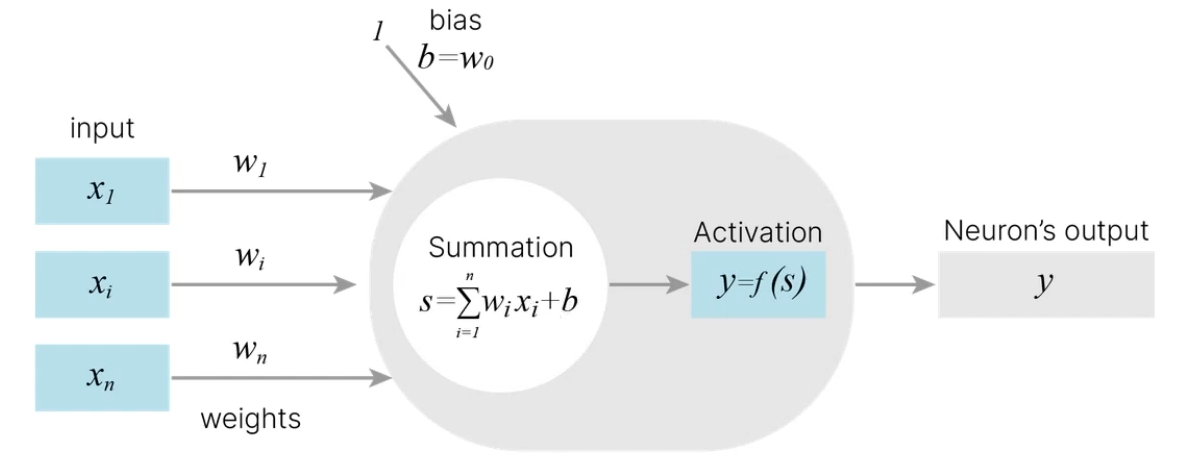

### Зачем нужна функция активации

Если соединить только линейные преобразования, их композиция всё равно будет линейным преобразованием. Такая сеть не сможет описывать многие нелинейные зависимости. Функция активации добавляет нелинейность.

В качестве примера рассмотрим ReLU:

$$\operatorname{ReLU}(z) = \max(0, z)$$

Она оставляет положительные значения без изменений и заменяет отрицательные нулём. В дальнейшем мы будем применять ReLU между полносвязными слоями.

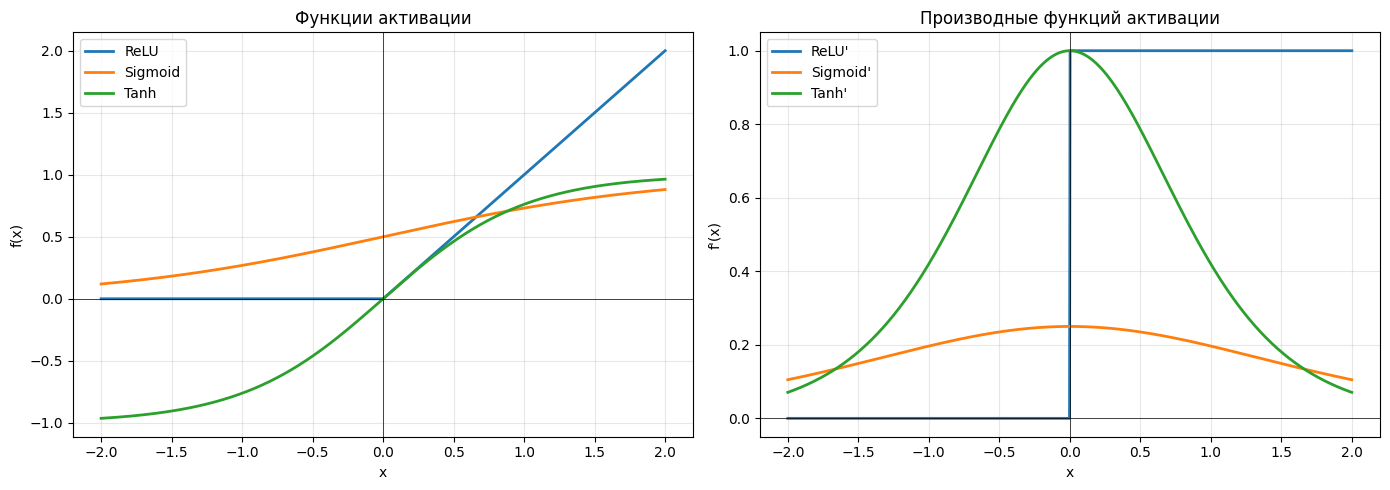

In [2]:
# Графики функций активации и их производных
import numpy as np
import matplotlib.pyplot as plt

# Диапазон значений x
x = np.linspace(-2, 2, 1000)

# Функции активации
relu = np.maximum(0, x)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)

# Производные
relu_derivative = np.where(x > 0, 1, 0)
sigmoid_derivative = sigmoid * (1 - sigmoid)
tanh_derivative = 1 - tanh**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x, relu, label="ReLU", linewidth=2)
ax1.plot(x, sigmoid, label="Sigmoid", linewidth=2)
ax1.plot(x, tanh, label="Tanh", linewidth=2)

ax1.set_title("Функции активации")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x)")
ax1.axhline(0, color="black", linewidth=0.5)
ax1.axvline(0, color="black", linewidth=0.5)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(x, relu_derivative, label="ReLU'", linewidth=2)
ax2.plot(x, sigmoid_derivative, label="Sigmoid'", linewidth=2)
ax2.plot(x, tanh_derivative, label="Tanh'", linewidth=2)

ax2.set_title("Производные функций активации")
ax2.set_xlabel("x")
ax2.set_ylabel("f'(x)")
ax2.axhline(0, color="black", linewidth=0.5)
ax2.axvline(0, color="black", linewidth=0.5)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## Обучение нейронной сети: прямой и обратный проход

Обучение - это подбор параметров, при которых модель делает меньшую ошибку на примерах. Типичный шаг обучения состоит из нескольких действий:

1. **Прямой проход (forward pass).** Данные проходят через сеть, и модель получает предсказания.

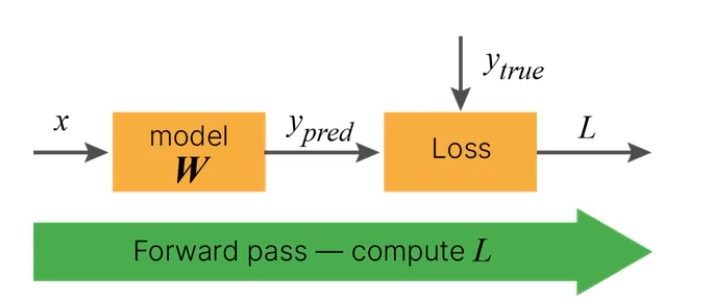

2. **Вычисление функции потерь.** Предсказания сравниваются с правильными ответами, получается одно число - значение loss для батча.
3. **Обратное распространение (backpropagation).** С помощью правила дифференцирования сложной функции рассчитывается, как изменится loss при небольшом изменении каждого обучаемого параметра. В PyTorch это обычно запускается вызовом `loss.backward()`.

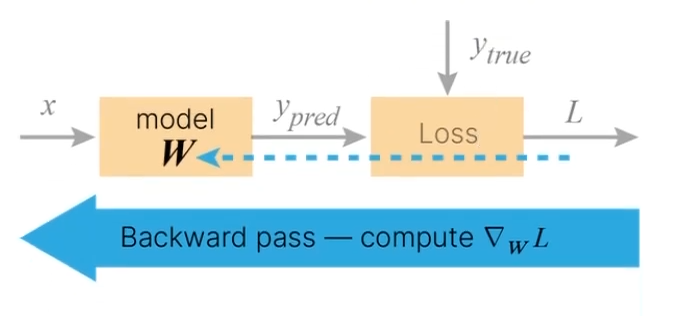

4. **Шаг оптимизатора.** Алгоритм оптимизации использует градиенты и изменяет параметры, например через `optimizer.step()`.

Для параметра $\theta$ градиент функции потерь $L$ показывает направление роста ошибки. Простейший градиентный спуск делает шаг в противоположном направлении:

$$\theta_{t+1} = \theta_t - \eta \frac{\partial L}{\partial \theta_t}$$

Здесь $\eta$ - скорость обучения (`learning rate`). Слишком большая скорость может приводить к скачкам и нестабильному обучению; слишком маленькая - к медленному улучшению.

**Backpropagation и оптимизатор - не одно и то же.** Обратное распространение вычисляет градиенты. Оптимизатор решает, как использовать их для изменения параметров. Градиенты не обновляют модель автоматически после `backward()` - для этого нужен `step()`.

## Возможности PyTorch

PyTorch - библиотека для вычислений с многомерными массивами и построения дифференцируемых моделей. Её основные компоненты:

- **`torch.Tensor`** - хранение чисел, выполнение арифметических операций и преобразований на CPU или GPU;
- **`torch.autograd`** - автоматическое вычисление градиентов операций, участвующих в вычислительном графе;
- **`torch.nn`** - готовые слои, функции активации и функции потерь, а также базовый класс `nn.Module` для собственных моделей;
- **`torch.optim`** - алгоритмы изменения параметров модели на основании рассчитанных градиентов;
- **`torch.utils.data`** - интерфейсы `Dataset` и `DataLoader` для хранения примеров и формирования батчей;
- **PyTorch Lightning** - высокоуровневая организация цикла обучения: запуск эпох, валидация, логирование и сохранение чекпойнтов.

PyTorch не обучает модель автоматически лишь потому, что создан объект `nn.Module`. Нужно определить функцию потерь, выбрать оптимизатор и организовать обучение. Lightning снимает значительную часть рутинного кода, но не отменяет необходимости понимать, что именно вычисляется.

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Тензоры: формы, типы данных и устройства

Тензор - основной объект для хранения данных в PyTorch. Скаляр можно рассматривать как тензор нулевой размерности, вектор - как тензор размерности 1, матрицу - как тензор размерности 2. Тензор может иметь и больше осей, например батч изображений часто имеет четыре измерения: `(batch, channels, height, width)`.

У тензора полезно проверять четыре свойства:

- `shape` - длина каждой оси;
- `ndim` - количество осей;
- `dtype` - тип хранимых значений;
- `device` - устройство, на котором хранится тензор.

`numel()` возвращает общее количество элементов. Например, у матрицы формы `(3, 4)` двенадцать элементов. Форма описывает организацию данных, но сама по себе не говорит об их смысле: матрица `(batch, features)` может хранить признаки объектов, а `(height, width)` - изображение.

Тип данных важен для корректности вычислений. Вещественные значения модели обычно хранятся как `torch.float32`; метки классов для `CrossEntropyLoss` обычно должны быть целочисленными индексами типа `torch.long`. Не все операции поддерживают все типы данных.

Тензоры также привязаны к устройству. Модель и входные данные должны находиться на одном устройстве. Перенос выполняется методом `.to(device)`. При этом CPU доступен всегда, а CUDA - только при наличии совместимого GPU и корректной конфигурации PyTorch.

In [4]:
# Создаём тензоры разных размерностей и выводим свойства, которые чаще всего нужно проверять при работе с данными.
# Скаляр имеет ноль измерений, вектор - одно, матрица - два; dtype определяет тип хранимых чисел.
scalar = torch.tensor(3.0, device=device)
vector = torch.tensor([1, 2, 3], dtype=torch.int64)
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

# Печатаем основные характеристики каждого тензора: форму, число измерений, тип, устройство и число элементов.
for name, tensor in [("scalar", scalar), ("vector", vector), ("matrix", matrix)]:
    print(
        f"{name}: shape={tuple(tensor.shape)}, ndim={tensor.ndim}, "
        f"dtype={tensor.dtype}, device={tensor.device}, numel={tensor.numel()}"
    )

# Метод to() создаёт представление матрицы с другим типом элементов, не меняя исходную matrix.
print("\nМатрица после преобразования в float64:")
print(matrix.to(dtype=torch.float64))

scalar: shape=(), ndim=0, dtype=torch.float32, device=cuda:0, numel=1
vector: shape=(3,), ndim=1, dtype=torch.int64, device=cpu, numel=3
matrix: shape=(2, 2), ndim=2, dtype=torch.float32, device=cpu, numel=4

Матрица после преобразования в float64:
tensor([[1., 2.],
        [3., 4.]], dtype=torch.float64)


## Индексирование и изменение формы

Индексирование позволяет выбрать отдельный элемент, строку, столбец или срез. Для матрицы `a` выражение `a[1]` выбирает строку с индексом 1, а `a[:, 0]` - первый столбец. Индексация в Python начинается с нуля, поэтому первый элемент имеет индекс `0`, второй - `1`.

Метод `reshape()` меняет форму тензора, не меняя число элементов. Если в исходном тензоре 12 значений, допустимы формы, произведение размеров которых равно 12: например `(3, 4)`, `(2, 6)` или `(12,)`. Форма `(5, 3)` не подходит, потому что в ней 15 позиций. Если PyTorch может представить результат как представление тех же данных, `reshape()` не требует копирования; иначе он может создать копию. Не следует полагаться на то, что любой `reshape()` разделяет память с исходным тензором.

In [5]:
# Исследуем индексы и срезы матрицы, а затем меняем форму тензора без изменения числа элементов.
# Создаём 12 целых чисел и сразу раскладываем их в матрицу из 3 строк и 4 столбцов.
a = torch.arange(12).reshape(3, 4)
print("Матрица a:\n", a)
# В выражении a[:, -1] двоеточие выбирает все строки, а -1 - последний столбец.
print("Последний столбец:", a[:, -1])
print("Элементы второй строки:", a[1])

# reshape меняет расположение тех же элементов; общее число элементов должно оставаться равным 12.
reshaped = a.reshape(2, 6)
print("\nФорма после reshape(2, 6):", tuple(reshaped.shape))
print(reshaped)
print("Число элементов:", a.numel())

# Форма (5, 3) невозможна: для неё потребовалось бы 15 элементов, а в a их только 12.
try:
    a.reshape(5, 3)
except RuntimeError as error:
    print("\nНевозможная форма:", error)

Матрица a:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Последний столбец: tensor([ 3,  7, 11])
Элементы второй строки: tensor([4, 5, 6, 7])

Форма после reshape(2, 6): (2, 6)
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])
Число элементов: 12

Невозможная форма: shape '[5, 3]' is invalid for input of size 12


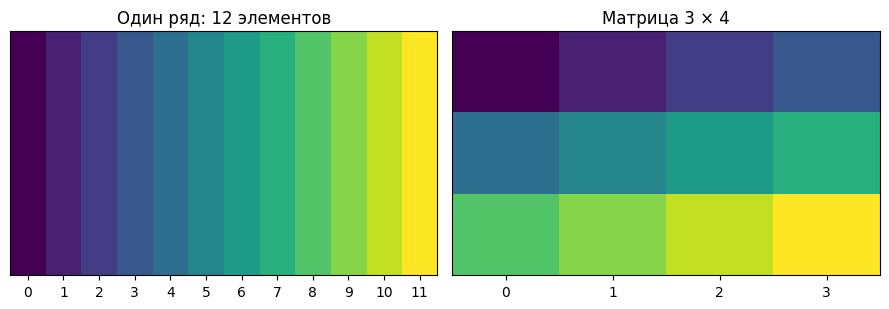

In [6]:
# Показываем, как те же 12 значений представлены сначала в одном ряду, а затем в матрице 3 × 4.
import matplotlib.pyplot as plt

# Создаём последовательность из 12 значений и её матричное представление - содержимое не меняется.
values = torch.arange(12, dtype=torch.float32)
reshaped_values = values.reshape(3, 4)

# Два графика позволяют сравнить линейное и двумерное представление одного набора значений.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

# Слева значения показаны одной строкой, справа - матрицей 3 × 4; цвет кодирует значение ячейки.
axes[0].imshow(values.numpy().reshape(1, -1), aspect="auto", cmap="viridis")
axes[0].set_title("Один ряд: 12 элементов")
axes[1].imshow(reshaped_values.numpy(), aspect="auto", cmap="viridis")
axes[1].set_title("Матрица 3 × 4")

# Убираем ненужные подписи по вертикали и ставим деления по горизонтали.
for ax in axes:
    ax.set_xticks(range(4 if ax is axes[1] else 12))
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Broadcasting - согласование форм

Broadcasting позволяет выполнять поэлементные операции над тензорами разных форм, если размеры их осей совместимы. PyTorch сравнивает размеры справа налево. Две оси совместимы, если размеры равны или один из них равен `1`. Отсутствующие слева оси мысленно считаются равными `1`.

Например, матрица формы `(3, 2)` и вектор формы `(2,)` совместимы: вектор применяется к каждой строке матрицы. Но матрица `(3, 2)` и вектор `(3,)` несовместимы: последний размер матрицы равен `2`, а последняя размерность вектора равна `3`.

Broadcasting не обязательно означает физическое копирование данных. Это правило интерпретации форм при операции. Оно удобно, но иногда ошибка в форме приводит к математически допустимой, однако неверной операции. Поэтому перед вычислением полезно явно проверять `shape` обоих аргументов.

In [7]:
# Сравниваем формы до и после broadcasting и показываем пример несовместимых размеров.
# Матрица имеет форму (3, 2), а вектор - (2,): его значения можно сопоставить каждому столбцу строки.
m = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
v = torch.tensor([10.0, 20.0])

print("Форма матрицы:", tuple(m.shape), "форма вектора:", tuple(v.shape))
# Broadcasting мысленно расширяет вектор вдоль первой оси, не копируя его вручную.
print("Сложение совместимых форм:\n", m + v)

# У вектора длины 3 размер справа не совпадает с размером столбцов матрицы, поэтому сложение не определено.
bad_v = torch.tensor([1.0, 2.0, 3.0])
print("\nФорма второго вектора:", tuple(bad_v.shape))
try:
    print(m + bad_v)
except RuntimeError as error:
    print("Несовместимые формы:", error)

Форма матрицы: (3, 2) форма вектора: (2,)
Сложение совместимых форм:
 tensor([[11., 22.],
        [13., 24.],
        [15., 26.]])

Форма второго вектора: (3,)
Несовместимые формы: The size of tensor a (2) must match the size of tensor b (3) at non-singleton dimension 1


## Автоматическое дифференцирование: `autograd`

PyTorch может автоматически вычислять производные по тензорам. Если тензор создан с `requires_grad=True`, то PyTorch отслеживает операции с ним, когда эти операции выполняются в обычном режиме градиентных вычислений. На основании выполненных операций строится вычислительный граф.

Когда вызывается `backward()` для скалярного результата, PyTorch проходит по графу в обратном направлении и вычисляет градиенты по нужным листовым тензорам. Для них результат записывается в атрибут `.grad`. Это позволяет не выводить вручную производные большой нейросети.

Возьмём функцию:

$$f(x,y) = x^2 + 3xy + \sin(y)$$

Её частные производные можно получить аналитически:

$$\frac{\partial f}{\partial x} = 2x + 3y, \qquad \frac{\partial f}{\partial y} = 3x + \cos(y)$$

Вычислим их вручную для конкретных значений и затем сравним с результатом PyTorch. Такой контроль полезен: он показывает, что `autograd` вычисляет производные от той функции, которую мы записали в коде.

In [8]:
# Считаем значение функции и её частные производные вручную для x = 2 и y = 1.
import math
from IPython.display import display_latex

# Функция f(x, y) = x² + 3xy + sin(y); фиксируем точку, в которой вычислим производные.
x_value = 2.0
y_value = 1.0

# Подставляем значения в саму функцию и в её частные производные по правилам дифференцирования.
f_value = x_value**2 + 3 * x_value * y_value + math.sin(y_value)
df_dx = 2 * x_value + 3 * y_value
df_dy = 3 * x_value + math.cos(y_value)

# Вывод нужен для сравнения с результатом, который далее получит autograd.
display_latex(f"$f(x, y) = {f_value:.6f}$", raw=True)
display_latex(rf"$\frac{{\partial f}}{{\partial x}} = {df_dx:.6f}$", raw=True)
display_latex(rf"$\frac{{\partial f}}{{\partial y}} = {df_dy:.6f}$", raw=True)

In [9]:
# Повторяем те же вычисления средствами autograd и сравниваем полученные градиенты с аналитическими.
# requires_grad=True просит PyTorch отслеживать операции с этими скалярами и строить вычислительный граф.
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(1.0, requires_grad=True)
# Операции над x и y формируют граф автоматически; формула совпадает с аналитическим примером из предыдущей ячейки.
f = x**2 + 3 * x * y + torch.sin(y)
# backward() вычисляет производные скалярной функции и записывает их в x.grad и y.grad.
f.backward()

# Сопоставляем градиенты PyTorch с формулами, вычисленными вручную.
display_latex(f"$f(x, y) = {f.item():.6f}$", raw=True)
display_latex(rf"$\frac{{\partial f}}{{\partial x}} = {x.grad.item():.6f}$", raw=True)
display_latex(rf"$\frac{{\partial f}}{{\partial y}} = {y.grad.item():.6f}$", raw=True)

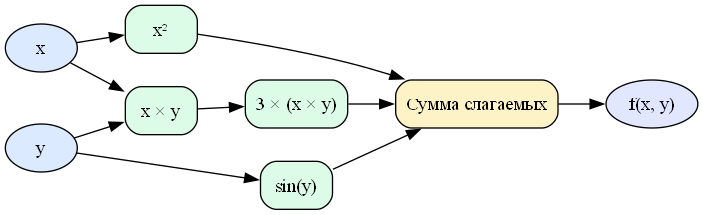

In [38]:
# Визуализируем вычислительный граф функции.
import graphviz
from graphviz import Digraph

graphviz.set_jupyter_format("png")

# Graphviz строит ориентированный граф: узлы - операции/значения, рёбра - зависимости между ними.
dot = Digraph("autograd_example", format="svg")
dot.attr(rankdir="LR", bgcolor="white", nodesep="0.35", ranksep="0.5")
dot.node("x", "x", shape="ellipse", style="filled", fillcolor="#dbeafe")
dot.node("y", "y", shape="ellipse", style="filled", fillcolor="#dbeafe")
dot.node("x2", "x²", shape="box", style="rounded,filled", fillcolor="#dcfce7")
dot.node("xy", "x × y", shape="box", style="rounded,filled", fillcolor="#dcfce7")
dot.node(
    "three", "3 × (x × y)", shape="box", style="rounded,filled", fillcolor="#dcfce7"
)
dot.node("siny", "sin(y)", shape="box", style="rounded,filled", fillcolor="#dcfce7")
dot.node(
    "sum",
    "Сумма слагаемых",
    shape="box",
    style="rounded,filled",
    fillcolor="#fef3c7",
)
dot.node("f", "f(x, y)", shape="ellipse", style="filled", fillcolor="#e0e7ff")

# Добавляем связи от исходных переменных к операциям, а затем от слагаемых к итоговой сумме.
dot.edge("x", "x2")
dot.edge("x", "xy")
dot.edge("y", "xy")
dot.edge("xy", "three")
dot.edge("y", "siny")
dot.edge("x2", "sum")
dot.edge("three", "sum")
dot.edge("siny", "sum")
dot.edge("sum", "f")
display(dot)

## `nn.Module`: как устроена модель

Обычно собственная нейросеть задаётся классом-наследником `torch.nn.Module`. В нём особенно важны два метода:

- `__init__()` объявляет слои и другие объекты, которые должны быть частью модели;
- `forward()` задаёт, как входные данные проходят через эти объекты.

`nn.Module` автоматически отслеживает вложенные модули и их обучаемые параметры. Поэтому `model.parameters()` возвращает параметры, которые нужно передать оптимизатору, а `model.to(device)` переносит зарегистрированные параметры и буферы на выбранное устройство.

### Параметры и буферы

**Параметры** - значения, которые обычно обучаются градиентным методом. Например, у `nn.Linear` это матрица `weight` и, если `bias=True`, вектор `bias`. Они доступны через `named_parameters()` и входят в `state_dict()`.

**Буферы** - тензоры, принадлежащие модулю, но не являющиеся обучаемыми параметрами. Например, `BatchNorm` хранит скользящие оценки среднего и дисперсии. Буферы перемещаются вместе с модулем и обычно сохраняются в `state_dict()`, но не передаются оптимизатору через `parameters()`.

### Вложенные модули и `state_dict`

Если сохранить слой в атрибуте `self.layer`, PyTorch зарегистрирует его как дочерний модуль. Если поместить несколько слоёв в `nn.Sequential`, данные будут передаваться через них по порядку. `state_dict()` возвращает словарь состояний параметров и буферов; его можно сохранить и затем загрузить в модель той же архитектуры.

Важно: `state_dict()` сохраняет состояние, а не описание всей архитектуры. Чтобы восстановить модель только из словаря, нужно сначала создать экземпляр совместимого класса.

## Классификатор `TinyClassifier`: `__init__` и `forward`

Для текущего примера создадим двухслойный полносвязный классификатор. Вход одного объекта содержит два числа, скрытый слой содержит 16 нейронов, а выходной слой - три числа для трёх классов.

В `__init__()`:

- `super().__init__()` инициализирует базовый класс `nn.Module`; без этого корректная регистрация модулей не будет работать;
- `nn.Linear(in_features, hidden_features)` создаёт обучаемое линейное преобразование из двух признаков в 16 значений;
- `nn.ReLU()` добавляет нелинейность;
- второй `nn.Linear(hidden_features, num_classes)` преобразует скрытое представление в три логита.

В `forward(x)` вход `x` имеет форму `(batch_size, 2)`. Сначала линейный слой преобразует его в `(batch_size, 16)`, ReLU сохраняет форму, а последний линейный слой возвращает `(batch_size, 3)`. Первый размер - количество объектов в текущем батче, а не часть архитектуры модели.

Не нужно вызывать `forward()` напрямую в обычном коде обучения. Выражение `model(x)` запускает стандартный механизм вызова модуля PyTorch и использует `forward()`.

In [39]:
# Определяем небольшую полносвязную сеть с одним скрытым слоем для классификации двумерных точек.
from torch import nn


# Модель наследуется от nn.Module, поэтому PyTorch автоматически отслеживает её вложенные слои и параметры.
class TinyClassifier(nn.Module):
    """
    Полносвязный классификатор для трёх классов по двум числовым признакам.

    Args:
        in_features: количество входных признаков одного объекта.
        hidden_features: количество нейронов в скрытом слое.
        num_classes: количество классов, для которых возвращаются логиты.
    """

    def __init__(
        self,
        in_features: int = 2,
        hidden_features: int = 16,
        num_classes: int = 3,
    ) -> None:
        """Создаёт линейные слои и функцию активации между ними."""
        # Инициализируем внутреннее состояние nn.Module до регистрации собственных слоёв.
        super().__init__()
        # Первый Linear преобразует два признака в hidden_features обучаемых представлений.
        self.linear1 = nn.Linear(in_features, hidden_features)
        # ReLU добавляет нелинейность: без неё два линейных слоя подряд сводились бы к одному линейному преобразованию.
        self.activation = nn.ReLU()
        # Последний Linear выдаёт по одному логиту на каждый класс; softmax здесь не нужен для CrossEntropyLoss.
        self.linear2 = nn.Linear(hidden_features, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Преобразует батч формы (batch_size, in_features) в логиты классов."""
        # Вход имеет форму (batch_size, in_features); первый слой меняет последнюю размерность на hidden_features.
        x = self.linear1(x)
        # Функция активации применяется поэлементно и сохраняет форму тензора.
        x = self.activation(x)
        # Возвращаем логиты формы (batch_size, num_classes), а не готовые вероятности.
        return self.linear2(x)


# Создаём экземпляр модели с параметрами по умолчанию и печатаем структуру вложенных модулей.
model = TinyClassifier()
print(model)

TinyClassifier(
  (linear1): Linear(in_features=2, out_features=16, bias=True)
  (activation): ReLU()
  (linear2): Linear(in_features=16, out_features=3, bias=True)
)


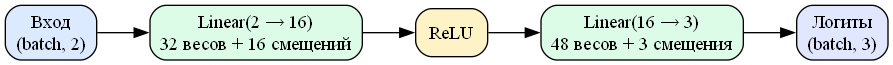

In [40]:
# Строим вычислительный граф TinyClassifier.
dot = Digraph("tiny_classifier", format="svg")
dot.attr(rankdir="LR", bgcolor="white", nodesep="0.4", ranksep="0.55")

# Создаём узлы по порядку выполнения: вход, скрытый Linear, ReLU, выходной Linear и логиты.
dot.node(
    "input",
    "Вход\n(batch, 2)",
    shape="box",
    style="rounded,filled",
    fillcolor="#dbeafe",
)
dot.node(
    "linear1",
    "Linear(2 → 16)\n32 весов + 16 смещений",
    shape="box",
    style="rounded,filled",
    fillcolor="#dcfce7",
)
dot.node("relu", "ReLU", shape="box", style="rounded,filled", fillcolor="#fef3c7")
dot.node(
    "linear2",
    "Linear(16 → 3)\n48 весов + 3 смещения",
    shape="box",
    style="rounded,filled",
    fillcolor="#dcfce7",
)
dot.node(
    "logits",
    "Логиты\n(batch, 3)",
    shape="box",
    style="rounded,filled",
    fillcolor="#e0e7ff",
)

# Стрелки показывают порядок прямого прохода между слоями.
dot.edge("input", "linear1")
dot.edge("linear1", "relu")
dot.edge("relu", "linear2")
dot.edge("linear2", "logits")
display(dot)

In [13]:
# Проверяем формы входа и выхода и считаем число обучаемых параметров каждого слоя и всей модели.
# Используем батч из 8 объектов: у каждого по 2 признака.
model = TinyClassifier(in_features=2, hidden_features=16, num_classes=3)
example_batch = torch.randn(8, 2)
# Прямой проход должен вернуть по три логита на каждый объект, поэтому ожидаем форму (8, 3).
logits = model(example_batch)
print("Вход:", tuple(example_batch.shape))
print("Выход:", tuple(logits.shape))

# named_parameters() перечисляет обучаемые веса и смещения; numel() считает число скалярных значений в каждом тензоре.
for name, parameter in model.named_parameters():
    print(f"{name}: shape={tuple(parameter.shape)}, parameters={parameter.numel()}")

# Для Linear число параметров равно in_features × out_features + out_features (смещения).
print("Всего параметров:", sum(parameter.numel() for parameter in model.parameters()))
print("Ожидаемое число: (2 × 16 + 16) + (16 × 3 + 3) = 99")

Вход: (8, 2)
Выход: (8, 3)
linear1.weight: shape=(16, 2), parameters=32
linear1.bias: shape=(16,), parameters=16
linear2.weight: shape=(3, 16), parameters=48
linear2.bias: shape=(3,), parameters=3
Всего параметров: 99
Ожидаемое число: (2 × 16 + 16) + (16 × 3 + 3) = 99


### Где здесь autograd

Параметры линейных слоёв по умолчанию имеют `requires_grad=True`. Поэтому операции `linear1(x)`, `ReLU` и `linear2(...)` участвуют в вычислительном графе, если градиенты не отключены контекстом вроде `torch.no_grad()` или `torch.inference_mode()`.

Прямой вызов `logits = model(x)` сам по себе не обучает модель. Он только вычисляет результат. Для обучения нужно рассчитать loss по правильным меткам, вызвать `loss.backward()`, а затем попросить оптимизатор изменить параметры через `optimizer.step()`. При оценке модели градиенты обычно не нужны.

## Градиенты параметров: что делает `backward()`

Рассмотрим loss классификатора на одном батче. После `loss.backward()` у параметров появляются градиенты в `.grad`. Их значение и знак помогают понять, в каком направлении следует менять параметр, чтобы уменьшить loss. Саму величину изменения задаёт алгоритм оптимизации.

Градиенты по умолчанию **накапливаются**: повторный вызов `backward()` добавит новые значения к уже имеющимся. Поэтому перед следующим шагом обычно вызывают `optimizer.zero_grad()`. В коде ниже мы отдельно покажем градиенты, но пока не будем менять параметры: это помогает отделить обратное распространение от шага оптимизатора.

In [14]:
# Вычисляем loss на синтетическом батче и проверяем, какие градиенты появились у параметров модели.
# Инициализируем модель и небольшой пример из трёх объектов; каждый объект относится к одному из трёх классов.
grad_model = TinyClassifier().to(device)
grad_x = torch.tensor(
    [[0.2, -0.4], [1.0, 0.7], [-0.8, 1.1]], dtype=torch.float32, device=device
)
grad_y = torch.tensor([0, 1, 2], dtype=torch.long, device=device)
criterion = nn.CrossEntropyLoss()

# Прямой проход получает логиты, а CrossEntropyLoss сравнивает их с целочисленными метками классов.
grad_logits = grad_model(grad_x)
grad_loss = criterion(grad_logits, grad_y)

# Вычисляем градиенты loss по всем обучаемым параметрам модели; веса пока не обновляются.
grad_loss.backward()
print(f"Loss: {grad_loss.item():.4f}")

# Проверяем, что градиенты появились у весов и смещений, и выводим их нормы.
for name, parameter in grad_model.named_parameters():
    norm = parameter.grad.norm().item() if parameter.grad is not None else 0.0
    print(f"{name}: норма градиента = {norm:.6f}")

Loss: 1.0761
linear1.weight: норма градиента = 0.205260
linear1.bias: норма градиента = 0.186806
linear2.weight: норма градиента = 0.525620
linear2.bias: норма градиента = 0.093077


## Функции потерь

Функция потерь переводит предсказания модели и правильные ответы в число, по которому можно вычислять градиенты и обучать параметры. Она задаёт, что именно считается ошибкой для данной задачи. Loss - не то же самое, что accuracy: loss использует численные предсказания и обычно содержит информацию об уверенности модели, тогда как accuracy считает только долю правильных классов.

### `CrossEntropyLoss` для классификации

В многоклассовой классификации модель возвращает логиты формы `(batch_size, num_classes)`. Правильные ответы - целочисленные индексы классов формы `(batch_size,)`, обычно `torch.long`. `nn.CrossEntropyLoss` объединяет вычисления, эквивалентные `LogSoftmax` и отрицательному логарифму вероятности правильного класса. Поэтому перед `CrossEntropyLoss` не надо добавлять `Softmax`: функция ожидает логиты.

Если модель уверенно назначает высокую вероятность правильному классу, потеря обычно мала. Если правильный класс получает низкую вероятность, потеря растёт. Такая функция подходит для обучения классификатора с несколькими взаимоисключающими классами.

### Другие распространённые функции

- `MSELoss` - среднеквадратичная ошибка, часто используемая в регрессии. Она усредняет квадраты разностей между предсказанными и истинными числами.
- `L1Loss` - среднее абсолютное отклонение; в отличие от MSE линейно штрафует величину ошибки.
- `BCEWithLogitsLoss` - бинарная кросс-энтропия для независимых бинарных ответов. Она также принимает логиты и сама выполняет численно устойчивую часть вычислений.

Функцию потерь выбирают по постановке задачи, а не по тому, какая из них чаще встречается в примерах. Неправильная комбинация форм выходов, типов меток и функции потерь может привести к ошибке или некорректному обучению.

## Оптимизаторы: SGD, Adam и AdamW

Оптимизатор обновляет параметры модели, используя градиенты, рассчитанные обратным распространением. Обычно его создают один раз перед обучением и передают ему параметры модели: `optimizer = torch.optim.AdamW(model.parameters(), ...)`.

### Скорость обучения

`lr` (`learning rate`) определяет масштаб обновлений. Если `lr` слишком велик, loss может колебаться или расти; если слишком мал, обучение может идти медленно. Значение скорости обучения часто важнее небольших изменений архитектуры, поэтому его стоит фиксировать в конфигурации эксперимента.

### SGD

Стохастический градиентный спуск делает шаг по градиенту текущего батча. Он прост и может работать очень хорошо, но чувствителен к настройке скорости обучения. Вариант с `momentum` накапливает сглаженное направление предыдущих градиентов, что может ускорять движение по устойчивым направлениям и уменьшать колебания.

### Adam

Adam адаптирует масштаб шага для разных параметров на основе скользящих оценок первого и второго моментов градиентов. Это часто делает его удобным стартовым вариантом, особенно когда пока нет уверенности, какая скорость обучения подойдёт задаче. Adam не отменяет настройку `lr` и не гарантирует лучшего результата для любой модели.

### AdamW

AdamW похож на Adam, но реализует `weight_decay` как отдельное затухание параметров, не смешивая его напрямую с оценками градиента. `weight_decay` обычно помогает ограничивать слишком большие значения параметров и может снижать переобучение. Слишком сильное затухание, однако, тоже мешает модели учиться.

Аргументы, которые полезно знать:

- `lr` - скорость обучения;
- `weight_decay` - сила затухания весов;
- `betas` - коэффициенты скользящих оценок в Adam/AdamW;
- `eps` - небольшое число для численной устойчивости;
- `momentum` - параметр инерции в SGD.

**Базовый оптимизатор для работ курса - AdamW.** Отправная точка: `lr=1e-3`, `weight_decay=1e-4`. Это не универсально оптимальные значения: их можно менять, если эксперимент показывает, что обучение идёт слишком медленно, нестабильно или модель переобучается. Для короткого синтетического примера ниже используется более высокая скорость обучения, чтобы быстро увидеть работу полного цикла.

## Воспроизводимость экспериментов и конфигурация

Обучение нейронной сети содержит случайные компоненты: начальную инициализацию параметров, перемешивание объектов, случайную генерацию данных и некоторые операции библиотек. Если каждое выполнение использует разные случайные числа, сравнивать два запуска сложнее.

**Seed** задаёт начальное состояние генераторов случайных чисел. Фиксация seed помогает повторять эксперимент, но не гарантирует побитовую идентичность между разным оборудованием, версиями библиотек и всеми CUDA-операциями (порядок выполнения независимых параллельных операций на видеокарте часто не гарантирован и не определён заранее).

Гиперпараметры лучше хранить отдельно от кода обучения. В этой работе мы зададим seed, размер батча, число эпох, learning rate и `weight_decay` в одном месте. Тогда сравнение конфигураций не потребует поиска констант по всему ноутбуку.

In [15]:
# Фиксируем основные источники случайности и собираем параметры эксперимента в одном месте.
import random
import numpy as np


# Фиксируем генераторы случайных чисел Python, NumPy и PyTorch, чтобы упростить повторение эксперимента.
def set_seed(seed: int = 42) -> None:
    """Фиксирует основные источники случайности для более воспроизводимого запуска."""
    # Синхронизируем источники случайности, которые используют разные библиотеки.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    # Если есть GPU, задаём seed и для CUDA-генераторов.
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Гиперпараметры собраны вместе, чтобы их можно было менять без поиска по всему ноутбуку.
SEED = 42
BATCH_SIZE = 64
MANUAL_EPOCHS = 20
LIGHTNING_EPOCHS = 20
MANUAL_LR = 1e-2
LIGHTNING_LR = 1e-2
WEIGHT_DECAY = 1e-3
# Вызываем настройку до генерации данных и инициализации моделей.
set_seed(SEED)

# Выводим текущую конфигурацию, чтобы параметры запуска были видны в результатах ноутбука.
print(
    {
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "manual_epochs": MANUAL_EPOCHS,
        "lightning_epochs": LIGHTNING_EPOCHS,
        "manual_lr": MANUAL_LR,
        "lightning_lr": LIGHTNING_LR,
        "weight_decay": WEIGHT_DECAY,
    }
)

{'seed': 42, 'batch_size': 64, 'manual_epochs': 20, 'lightning_epochs': 20, 'manual_lr': 0.01, 'lightning_lr': 0.01, 'weight_decay': 0.001}


## Данные: `Dataset`, `DataLoader` и мини-батчи

В задаче обучения важно разделить описание одного примера и процесс выдачи примеров модели.

- **`Dataset`** описывает коллекцию примеров. `__len__()` возвращает число объектов, а `__getitem__(idx)` - один объект и его метку.
- **`DataLoader`** получает `Dataset` и выдаёт данные батчами. Он управляет формированием батчей, перемешиванием, а при необходимости - параллельной загрузкой.
- **Батч** - небольшая группа объектов, обрабатываемая за один прямой и обратный проход. Градиент батча используется для одного обновления параметров.

Обучение на батчах обычно эффективнее обработки по одному примеру и требует меньше памяти, чем обработка всего датасета за раз. Последний батч может содержать меньше объектов, если размер датасета не делится на `batch_size`.

Мы создадим простую задачу классификации: три облака точек на плоскости. Каждый объект содержит два вещественных признака, а метка принимает значение `0`, `1` или `2`. Внешняя библиотека с готовым датасетом здесь не нужна.

In [16]:
# Определяем собственный Dataset и генерируем три облака двумерных точек с целочисленными метками.
from torch.utils.data import Dataset, DataLoader, random_split
from typing import TypeAlias

# Удобный псевдоним описывает один элемент датасета: тензор признаков и тензор метки.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]


# Dataset определяет два обязательных действия: сообщить длину и вернуть объект по индексу.
class PointsDataset(Dataset[TensorPair]):
    """Набор двумерных точек и целочисленных меток классов."""

    def __init__(self, features: torch.Tensor, labels: torch.Tensor) -> None:
        """Сохраняет признаки и метки, проверяя согласованность размерностей."""
        # Проверяем контракт: features должны иметь форму (число объектов, число признаков).
        if features.ndim != 2:
            raise ValueError(
                "features должен иметь форму (число объектов, число признаков)"
            )
        if labels.ndim != 1:
            raise ValueError("labels должен быть одномерным тензором")
        if len(features) != len(labels):
            raise ValueError("Число объектов должно совпадать с числом меток")

        # CrossEntropyLoss ожидает целочисленные метки типа long; признаки приводим к float32 для линейных слоёв.
        self.features = features.to(dtype=torch.float32)
        self.labels = labels.to(dtype=torch.long)

    # DataLoader использует длину Dataset, чтобы знать число доступных примеров.
    def __len__(self) -> int:
        """Возвращает число примеров в датасете."""
        return len(self.labels)

    # Возвращаем одну пару: вектор признаков формы (2,) и скалярную метку.
    def __getitem__(self, idx: int) -> TensorPair:
        """Возвращает признаки формы (2,) и одну метку формы ()."""
        return self.features[idx], self.labels[idx]


# Генератор использует фиксированный seed, поэтому облака воспроизводятся при повторном запуске.
generator = torch.Generator().manual_seed(SEED)

# Задаём центры трёх классов. Вокруг каждого центра будут сгенерированы точки с шумом.
centers = torch.tensor([[-2.0, -1.2], [2.0, -1.0], [0.0, 2.0]])
points_per_class = 500
spread = 0.8

# Генерируем points_per_class точек вокруг каждого центра; spread задаёт разброс облака.
features = torch.cat(
    [
        centers[k] + spread * torch.randn(points_per_class, 2, generator=generator)
        for k in range(len(centers))
    ]
)

# Каждому облаку присваиваем метку 0, 1 или 2 в том же порядке, что и признаки.
labels = torch.cat(
    [torch.full((points_per_class,), k, dtype=torch.long) for k in range(len(centers))]
)

# Упаковываем тензоры в Dataset и проверяем, какой объект возвращает индексирование.
dataset = PointsDataset(features, labels)
print("Число объектов:", len(dataset))
print("Форма признаков всего датасета:", tuple(dataset.features.shape))
print("Форма меток всего датасета:", tuple(dataset.labels.shape))
print("Один пример:", dataset[0])

Число объектов: 1500
Форма признаков всего датасета: (1500, 2)
Форма меток всего датасета: (1500,)
Один пример: (tensor([-0.4585, -0.0102]), tensor(0))


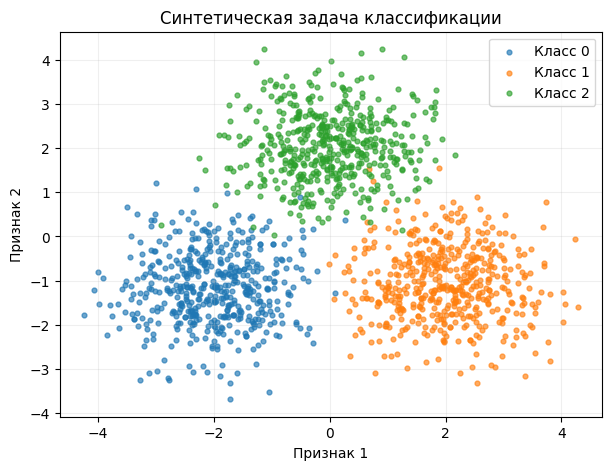

In [17]:
# Показываем исходную задачу на плоскости: координаты точек являются признаками, цвет - меткой класса.
# Matplotlib работает с NumPy-массивами; здесь данные остаются на CPU, поэтому преобразование безопасно.
features_np = features.numpy()
labels_np = labels.numpy()
plt.figure(figsize=(7, 5))

# Рисуем каждый класс отдельно, чтобы цвет и легенда отражали целевую метку.
for class_id in range(3):
    mask = labels_np == class_id
    plt.scatter(
        features_np[mask, 0],
        features_np[mask, 1],
        s=12,
        alpha=0.65,
        label=f"Класс {class_id}",
    )

# Подписываем оси и добавляем легенду, чтобы график можно было интерпретировать без чтения кода.
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Синтетическая задача классификации")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Обучающая, валидационная и тестовая выборки

Модель нельзя честно оценить только на тех примерах, по которым она обновляла параметры. Поэтому данные делят на независимые части:

- **обучающая выборка (train)** используется для вычисления градиентов и обновления параметров;
- **валидационная выборка (validation)** помогает сравнивать варианты модели, отслеживать качество по эпохам и принимать решения о настройках;
- **тестовая выборка (test)** используется для финальной оценки выбранного решения. Её результаты не должны использоваться для подбора гиперпараметров.

В этой работе используем разделение 70% / 15% / 15%. `random_split()` создаёт подмножества исходного датасета. Затем для каждой части создаётся отдельный `DataLoader`. Перемешивание включаем для train, чтобы порядок примеров не был одинаковым каждую эпоху. Для validation и test перемешивание не требуется.

При реальных задачах важно учитывать структуру данных: например, кадры одного видео или записи одного пользователя не всегда можно случайно распределить между всеми частями, поскольку это может приводить к утечке информации. Здесь данные синтетические и независимые, поэтому случайное разделение подходит.

In [18]:
# Разделяем датасет на train, validation и test и создаём DataLoader для каждой части.
# Отводим 70% данных для обучения, 15% для настройки модели и оставшиеся 15% для итоговой проверки.
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

# Фиксированный генератор делает разбиение воспроизводимым при повторном запуске.
split_generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds, test_ds = random_split(
    dataset, [train_size, val_size, test_size], generator=split_generator
)

# Перемешиваем только train: порядок validation и test должен оставаться стабильным для оценки.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Проверяем размеры частей и форму одного мини-батча, выдаваемого DataLoader.
print(f"Train: {len(train_ds)} объектов")
print(f"Validation: {len(val_ds)} объектов")
print(f"Test: {len(test_ds)} объектов")

xb, yb = next(iter(train_loader))
print("Форма батча признаков:", tuple(xb.shape))
print("Форма батча меток:", tuple(yb.shape), "dtype:", yb.dtype)

Train: 1050 объектов
Validation: 225 объектов
Test: 225 объектов
Форма батча признаков: (64, 2)
Форма батча меток: (64,) dtype: torch.int64


Для классификации важно проверить не только размеры выборок, но и то, что в каждой части представлены все классы. Ниже мы посчитаем число примеров каждого класса. В реальной задаче при сильном дисбалансе классов может потребоваться стратифицированное разделение данных.

In [19]:
# Подсчитываем количество примеров каждого класса в каждом подмножестве данных.
# Подсчёт помогает заметить, если случайное разбиение оставило какой-либо класс почти без примеров.


def class_counts(subset: Dataset[TensorPair], num_classes: int = 3) -> torch.Tensor:
    """Подсчитывает число примеров каждого класса в подмножестве."""
    # Собираем скалярные метки из подмножества в одномерный тензор.
    all_labels = torch.tensor([int(subset[i][1]) for i in range(len(subset))])
    # minlength сохраняет три позиции даже если в подмножестве случайно нет примеров одного класса.
    return torch.bincount(all_labels, minlength=num_classes)


# Сравниваем распределения меток между train, validation и test.
print("Train:", class_counts(train_ds).tolist())
print("Validation:", class_counts(val_ds).tolist())
print("Test:", class_counts(test_ds).tolist())

Train: [349, 341, 360]
Validation: [75, 89, 61]
Test: [76, 70, 79]


## Один шаг обучения вручную

Соберём компоненты в один шаг обучения. Здесь видно, какие действия PyTorch выполняет автоматически, а за какие отвечает наш код:

1. `model.train()` переводит модуль в режим обучения;
2. `optimizer.zero_grad()` очищает градиенты с прошлого шага;
3. `model(xb)` вычисляет логиты на текущем батче;
4. `criterion(logits, yb)` вычисляет loss;
5. `loss.backward()` вычисляет градиенты параметров;
6. `optimizer.step()` обновляет параметры.

Мы выберем `CrossEntropyLoss` и `AdamW`. В `AdamW` укажем скорость обучения и коэффициент `weight_decay` из конфигурации. До и после шага сохраним один параметр, чтобы убедиться, что оптимизатор действительно изменил состояние модели.

In [20]:
# Выполняем один полный шаг обучения и наблюдаем loss, величину градиента и изменение параметра.
# Фиксируем инициализацию этой модели отдельно от генерации датасета.
torch.manual_seed(SEED + 1)

# Создаём модель и переносим её параметры на то же устройство, где будут данные.
manual_model = TinyClassifier().to(device)

# Для многоклассовой задачи используем cross-entropy: на вход подаются логиты и целочисленные метки.
criterion = nn.CrossEntropyLoss()

# AdamW адаптивно меняет шаг для каждого параметра; weight_decay задаёт отдельное затухание весов.
manual_optimizer = torch.optim.AdamW(
    manual_model.parameters(), lr=MANUAL_LR, weight_decay=WEIGHT_DECAY
)

# Берём один мини-батч и переносим признаки и метки на выбранное устройство.
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

# Сохраняем копию первого параметра до обновления, чтобы затем измерить реальное изменение.
parameter_before = next(manual_model.parameters()).detach().clone()

# Включаем режим обучения; это важно для слоёв вроде Dropout и BatchNorm, если они появятся в модели.
manual_model.train()

# Обнуляем старые градиенты: по умолчанию PyTorch накапливает их между вызовами backward().
manual_optimizer.zero_grad(set_to_none=True)

# Прямой проход получает логиты для всех объектов батча.
logits = manual_model(xb)

# Loss - одно число, измеряющее несоответствие логитов правильным меткам.
loss = criterion(logits, yb)

# Обратный проход вычисляет d(loss)/d(parameter) и записывает градиенты в .grad.
loss.backward()

# Смотрим на градиент одного параметра: его норма показывает общий масштаб производных.
first_parameter = next(manual_model.parameters())
grad_norm = (
    first_parameter.grad.norm().item() if first_parameter.grad is not None else 0.0
)

# Оптимизатор использует рассчитанные градиенты, чтобы изменить параметры модели.
manual_optimizer.step()

# Сравниваем параметр после обновления с копией до него и находим максимальный модуль изменения.
parameter_change = (first_parameter.detach() - parameter_before).abs().max().item()

# Выводим три наблюдения, по которым можно убедиться, что полный шаг действительно состоялся.
print(f"Loss на одном батче: {loss.item():.4f}")
print(f"Норма градиента первого параметра: {grad_norm:.6f}")
print(f"Максимальное изменение параметра: {parameter_change:.8f}")

Loss на одном батче: 1.4022
Норма градиента первого параметра: 0.588657
Максимальное изменение параметра: 0.01000619


Важная деталь: `zero_grad()` вызывается перед вычислением градиентов следующего батча, потому что PyTorch по умолчанию накапливает `.grad`. `set_to_none=True` оставляет градиенты в состоянии `None` до следующего вычисления; это поддерживается оптимизаторами PyTorch и часто экономит немного памяти.

Значение loss на одном батче ещё не характеризует качество обучения. Один батч может быть нетипичным. Поэтому в полноценном цикле нужно обработать все батчи эпохи и агрегировать метрики.

## Полный цикл: эпоха обучения и оценка

**Эпоха** - один проход по всем батчам обучающей выборки. Во время обучения градиенты вычисляются, а параметры обновляются. При проверке на validation параметры не должны изменяться: мы только выполняем прямой проход и считаем метрики.

Для этого нужны два механизма:

- `model.train()` и `model.eval()` задают режим модулей. Эти режимы особенно важны для таких слоёв, как Dropout и BatchNorm. Они не включают и не выключают autograd сами по себе.
- `torch.inference_mode()` отключает построение графа градиентов и подходит для обычной оценки модели. Это снижает накладные расходы, поскольку градиенты во время оценки не нужны.

Функция `run_epoch()` ниже выполняет одну эпоху обучения, если передан оптимизатор, или только оценку, если `optimizer=None`. Потери усредняются с учётом размера каждого батча, чтобы неполный последний батч не имел такого же веса, как полный.

In [21]:
# Выносим обработку одного прохода по DataLoader в функцию, которая поддерживает как обучение, так и оценку.
from tqdm import tqdm


def run_epoch(
    model: nn.Module,
    loader: DataLoader[TensorPair],
    criterion: nn.Module,
    device: torch.device,
    optimizer: torch.optim.Optimizer | None = None,
) -> tuple[float, float]:
    """
    Выполняет эпоху обучения или оценки и возвращает средние loss и accuracy.

    Если optimizer передан, параметры модели обновляются. Если optimizer равен None,
    вычисление выполняется в inference_mode и без обновления параметров.
    """
    # Наличие оптимизатора означает обучающий режим; без него функция только измеряет качество.
    training = optimizer is not None

    # train(True) включает поведение обучения, а train(False) эквивалентен eval() для слоя модели.
    model.train(training)
    total_loss = 0.0
    correct = 0
    total = 0

    # Во время обучения нужны градиенты; при оценке inference_mode экономит память и запрещает построение графа.
    context = torch.enable_grad() if training else torch.inference_mode()

    with context:
        # DataLoader отдаёт признаки и метки мини-батчами; переносим оба тензора на устройство модели.
        # Полезно использовать progress bar для наблюдения за процессом обучения.
        for features_batch, labels_batch in tqdm(
            loader, total=len(loader), leave=False
        ):
            features_batch = features_batch.to(device)
            labels_batch = labels_batch.to(device)

            # Перед каждым батчем очищаем накопленные градиенты, чтобы обновление относилось только к текущему батчу.
            if training:
                optimizer.zero_grad(set_to_none=True)

            # Прямой проход и функция потерь одинаковы для обучения и оценки.
            logits = model(features_batch)
            loss = criterion(logits, labels_batch)

            if training:
                # Вычисляем градиенты только в режиме обучения.
                loss.backward()
                # Меняем веса после вычисления градиентов.
                optimizer.step()

            # Умножаем средний loss батча на его размер, чтобы итоговое среднее учитывало последний неполный батч.
            batch_size = labels_batch.shape[0]
            total_loss += loss.detach().item() * batch_size

            # argmax выбирает класс с наибольшим логитом; сравниваем его с истинной меткой.
            correct += (logits.argmax(dim=1) == labels_batch).sum().item()
            total += batch_size

    # Возвращаем средний loss и долю верных предсказаний по всем объектам эпохи.
    return total_loss / total, correct / total

Теперь вызываем `run_epoch()` для train и validation в цикле по эпохам и сохраняем историю. Хранить историю полезно, потому что по одной итоговой метрике нельзя понять, как проходило обучение.

In [22]:
# Обучаем TinyClassifier заданное число эпох и сохраняем loss и accuracy для train и validation.
# Списки истории нужны для построения графиков после завершения обучения.
manual_history: dict[str, list[float]] = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

# Каждая эпоха проходит по всему train-loader, затем отдельно оценивает validation-loader.
for epoch in range(MANUAL_EPOCHS):
    # Передаём оптимизатор только при обучении: run_epoch выполнит backward() и обновит параметры.
    train_loss, train_accuracy = run_epoch(
        manual_model, train_loader, criterion, device, manual_optimizer
    )
    # При validation оптимизатор не передаётся, поэтому веса не меняются и градиенты не вычисляются.
    val_loss, val_accuracy = run_epoch(manual_model, val_loader, criterion, device)

    # Сохраняем метрики каждой эпохи, чтобы можно было сравнить динамику train и validation.
    manual_history["train_loss"].append(train_loss)
    manual_history["val_loss"].append(val_loss)
    manual_history["train_accuracy"].append(train_accuracy)
    manual_history["val_accuracy"].append(val_accuracy)

    # Краткая строка журнала позволяет следить за сходимостью прямо во время выполнения.
    print(
        f"Эпоха {epoch + 1:02d}/{MANUAL_EPOCHS} | "
        f"train loss={train_loss:.4f}, val loss={val_loss:.4f}, "
        f"train acc={train_accuracy:.3f}, val acc={val_accuracy:.3f}"
    )

Эпоха 01/20 | train loss=0.7564, val loss=0.3248, train acc=0.707, val acc=0.996


Эпоха 02/20 | train loss=0.2037, val loss=0.0918, train acc=0.988, val acc=0.996


Эпоха 03/20 | train loss=0.0803, val loss=0.0447, train acc=0.986, val acc=1.000


Эпоха 04/20 | train loss=0.0572, val loss=0.0312, train acc=0.987, val acc=1.000


Эпоха 05/20 | train loss=0.0513, val loss=0.0244, train acc=0.989, val acc=1.000


Эпоха 06/20 | train loss=0.0475, val loss=0.0219, train acc=0.989, val acc=1.000


... (10 outputs left out)

Эпоха 17/20 | train loss=0.0410, val loss=0.0118, train acc=0.990, val acc=1.000


Эпоха 18/20 | train loss=0.0407, val loss=0.0115, train acc=0.990, val acc=1.000


Эпоха 19/20 | train loss=0.0400, val loss=0.0113, train acc=0.990, val acc=1.000


Эпоха 20/20 | train loss=0.0408, val loss=0.0116, train acc=0.989, val acc=1.000


## Как читать графики обучения

На графике loss мы ожидаем, что ошибка на обучающей выборке будет уменьшаться. Валидационная ошибка вначале тоже часто падает. Если train loss продолжает уменьшаться, а val loss растёт, это может быть признаком переобучения: модель всё лучше подстраивается под тренировочные примеры, но хуже переносит закономерности на невиданные данные.

Accuracy показывает долю верных предсказаний. Она может оставаться неизменной, даже если loss меняется: например, модель может делать те же классификационные решения, но становиться более или менее уверенной в них.

Не нужно ожидать строго монотонных кривых. Обучение идёт по батчам, и значения могут колебаться. Графики - средство диагностики, а не доказательство качества модели сами по себе.

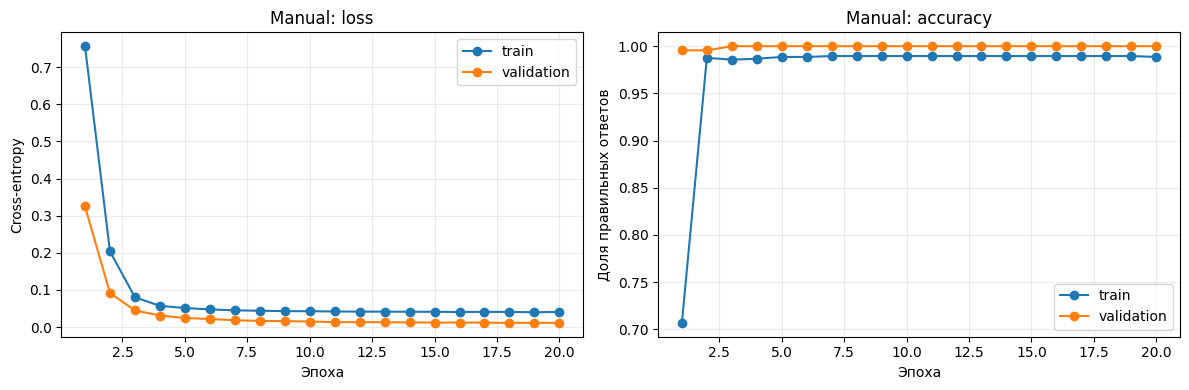

In [23]:
# Строим кривые train/validation loss и accuracy, чтобы визуально оценить ход обучения.
# Ось X - номера эпох; слева сравниваем loss, справа - долю верных ответов.
epochs = range(1, MANUAL_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Если train loss уменьшается, но validation loss растёт, это может указывать на переобучение.
axes[0].plot(epochs, manual_history["train_loss"], marker="o", label="train")
axes[0].plot(epochs, manual_history["val_loss"], marker="o", label="validation")
axes[0].set_title("Manual: loss")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Accuracy дополняет loss: модель может становиться увереннее даже тогда, когда доля ошибок меняется мало.
axes[1].plot(epochs, manual_history["train_accuracy"], marker="o", label="train")
axes[1].plot(epochs, manual_history["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Manual: accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Доля правильных ответов")
axes[1].legend()
axes[1].grid(alpha=0.25)

# Выравниваем подписи и показываем оба графика.
plt.tight_layout()
plt.show()

## PyTorch Lightning: обучение без ручной инфраструктуры

В ручном цикле мы сами управляли эпохами, переносом батчей на устройство, вызовами `zero_grad()`, `backward()` и `step()`, а также сбором метрик. В большом проекте в этот код добавляются чекпойнты, логирование, ранняя остановка, работа на разных устройствах и другие детали.

PyTorch Lightning отделяет **описание шага модели** от **организации обучения**:

- `LightningModule` содержит прямой проход, шаги обучения/валидации/тестирования и конфигурацию оптимизатора;
- `Trainer` запускает обучение, организует валидацию и управляет доступным оборудованием;
- callbacks выполняют дополнительные действия, например раннюю остановку или сохранение лучшего чекпойнта;
- logger записывает значения метрик, чтобы их можно было анализировать после запуска.

Lightning не угадывает задачу автоматически: мы должны определить правильную функцию потерь, метрики и оптимизатор. Основной алгоритм остаётся тем же, что и в ручном варианте, но рутинный цикл выполняет `Trainer`.

In [ ]:
%pip install lightning -qU

In [ ]:
# Определяем LightningModule, в котором описаны прямой проход, метрики train/validation/test и оптимизатор AdamW.

import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

import logging
import os
import warnings

# Отключаем ненужное логирование.
os.environ["LT_CLOUD"] = "0"

warnings.filterwarnings("ignore")

logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)


# LightningModule описывает модель и этапы работы с батчем, оставляя общий цикл обучения объекту Trainer.
class LitClassifier(L.LightningModule):
    """
    Многоклассовый классификатор с обучением под управлением Lightning.

    Args:
        in_features: число признаков одного объекта.
        hidden_features: число нейронов скрытого слоя.
        num_classes: число целевых классов.
        lr: learning rate оптимизатора AdamW.
        weight_decay: коэффициент затухания весов в AdamW.
    """

    def __init__(
        self,
        in_features: int = 2,
        hidden_features: int = 16,
        num_classes: int = 3,
        lr: float = 1e-2,
        weight_decay: float = 1e-3,
    ) -> None:
        """Инициализирует классификатор и сохраняет гиперпараметры чекпойнта."""

        # Инициализируем базовый LightningModule; без этого внутренний механизм Lightning не будет настроен.
        super().__init__()

        # Сохраняем аргументы конструктора внутри модуля и в чекпойнте для восстановления модели.
        self.save_hyperparameters()

        # Переиспользуем обычную архитектуру, чтобы отличалась организация обучения, а не сама модель.
        self.model = TinyClassifier(
            in_features=in_features,
            hidden_features=hidden_features,
            num_classes=num_classes,
        )

        # Один и тот же критерий применяется на train, validation и test.
        self.criterion = nn.CrossEntropyLoss()

    # forward задаёт предсказание; Lightning и PyTorch вызывают его через self(batch_features).
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты модели для входного батча."""
        return self.model(x)

    def training_step(self, batch: TensorPair, batch_idx: int) -> torch.Tensor:
        """Вычисляет loss на train-батче; Lightning использует его для backward и шага оптимизатора."""

        # Dataset/DataLoader возвращает признаки и метки; модель получает только признаки.
        features_batch, labels_batch = batch

        # Прямой проход даёт логиты формы (batch_size, num_classes).
        logits = self(features_batch)

        # CrossEntropyLoss сравнивает логиты с целочисленными правильными классами.
        loss = self.criterion(logits, labels_batch)

        # Для каждого объекта берём класс с максимальным логитом и считаем долю совпадений с метками.
        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        # log() сохраняет метрики в логгер; on_epoch=True просит агрегировать их за эпоху.
        self.log(
            "train_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "train_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

        # Trainer использует возвращённый loss для автоматического backward и шага AdamW.
        return loss

    # Validation измеряет качество на данных, которые не обновляют параметры модели.
    def validation_step(self, batch: TensorPair, batch_idx: int) -> None:
        """Считает validation-метрики без обновления параметров модели."""

        # Получаем предсказания и loss для текущего батча; метки не входят в прямой проход.
        features_batch, labels_batch = batch

        logits = self(features_batch)

        loss = self.criterion(logits, labels_batch)

        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        self.log(
            "val_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "val_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

    # Test запускается после выбора модели и предназначен для финальной независимой оценки.
    def test_step(self, batch: TensorPair, batch_idx: int) -> None:
        """Регистрирует финальные метрики на отложенной тестовой выборке."""

        # Извлекаем признаки и метки из отложенного тестового мини-батча.
        features_batch, labels_batch = batch

        # Выполняем предсказание и измеряем ошибку на ранее не использованных для настройки данных.
        logits = self(features_batch)

        loss = self.criterion(logits, labels_batch)

        # Доля правильных классов помогает интерпретировать значение loss.
        accuracy = (logits.argmax(dim=1) == labels_batch).float().mean()

        # Сохраняем тестовые метрики в журнале; они не участвуют в выборе чекпойнта.
        self.log(
            "test_loss",
            loss,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

        self.log(
            "test_accuracy",
            accuracy,
            on_step=False,
            on_epoch=True,
            batch_size=labels_batch.size(0),
        )

    # Lightning вызывает этот метод, чтобы получить оптимизатор, которым Trainer будет обновлять параметры.
    def configure_optimizers(self) -> torch.optim.Optimizer:
        """Создаёт базовый оптимизатор AdamW для параметров сети."""

        # Используем рекомендованный для курса baseline AdamW; скорость обучения и weight decay берём из hparams.
        return torch.optim.AdamW(
            self.parameters(),
            lr=float(self.hparams.lr),
            weight_decay=float(self.hparams.weight_decay),
        )

В `training_step()` мы возвращаем loss. На его основе `Trainer` выполняет обратное распространение и обновляет параметры с помощью оптимизатора, который возвращает `configure_optimizers()`. Поэтому в этом методе не нужно вручную вызывать `loss.backward()` и `optimizer.step()`.

В `validation_step()` мы вычисляем те же типы показателей, но не возвращаем шаг обучения и не обновляем параметры. Значения передаются в `self.log()`: `on_epoch=True` означает, что метрика агрегируется по эпохе. Аргумент `batch_size` нужен для корректного взвешивания агрегированных показателей, в том числе при неполном последнем батче.

In [25]:
from pathlib import Path

# Настраиваем Trainer, логгер, раннюю остановку и сохранение лучшего чекпойнта, затем запускаем обучение Lightning.
# Lightning задаёт seed также для своих механизмов и рабочих процессов, где это применимо.
L.seed_everything(SEED, workers=True, verbose=False)
lightning_model = LitClassifier(lr=LIGHTNING_LR, weight_decay=WEIGHT_DECAY)

# Сохраняем лучший чекпойнт по минимальному val_loss, а save_last дополнительно оставляет последний запуск.
checkpoint_callback = ModelCheckpoint(
    dirpath="checkpoints",
    filename="classifier-{epoch:02d}-{val_loss:.4f}",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    save_last=True,
)

# Если val_loss не улучшается пять эпох, обучение останавливается раньше max_epochs.
early_stopping = EarlyStopping(monitor="val_loss", mode="min", patience=5)

# CSVLogger записывает метрики в файл, откуда ниже построим графики без ручного сбора значений.
csv_logger = CSVLogger(save_dir="logs", name="pytorch_fundamentals-classifier")

# Trainer берёт на себя цикл эпох, переключение режимов, backward, optimizer.step и валидацию.
trainer = L.Trainer(
    max_epochs=LIGHTNING_EPOCHS,
    accelerator="auto",
    devices=1,
    logger=csv_logger,
    callbacks=[checkpoint_callback, early_stopping],
    deterministic=True,
    log_every_n_steps=1,
    enable_progress_bar=True,
)

# Запускаем обучение: train-loader обновляет параметры, validation-loader оценивает эпоху и управляет callbacks.
trainer.fit(lightning_model, train_dataloaders=train_loader, val_dataloaders=val_loader)

# Выводим путь к лучшему сохранённому состоянию и достигнутую им validation loss.
best_model_path = Path(checkpoint_callback.best_model_path)
print("Лучший чекпойнт:", best_model_path.name)
print("Лучший val_loss:", checkpoint_callback.best_model_score)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (13 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Лучший чекпойнт: classifier-epoch=18-val_loss=0.0108-v6.ckpt
Лучший val_loss: tensor(0.0108, device='cuda:0')


### Что сохраняет Lightning

`ModelCheckpoint` отслеживает выбранную метрику - здесь `val_loss` - и сохраняет лучший чекпойнт. `mode="min"` означает, что меньшая потеря считается лучшим результатом. `save_last=True` дополнительно сохраняет последнее состояние обучения. Чекпойнт Lightning включает не только состояние модели, но и информацию, необходимую для продолжения или восстановления соответствующего эксперимента.

`EarlyStopping` завершает обучение, если выбранная метрика не улучшается заданное число проверок. Это не гарантирует, что найден глобально лучший вариант, но помогает не тратить эпохи на отсутствие прогресса.

CSVLogger записывает метрики в CSV-файл. По ним можно построить графики или сравнивать запуски. Названия метрик в коде и на графиках должны совпадать - это уменьшает вероятность случайно сравнить разные величины.

## Графики из логов Lightning

Метрики CSVLogger сохраняются в файле `metrics.csv` внутри папки текущего запуска. Логирование может записывать отдельные значения на разных этапах эпохи, поэтому ниже мы группируем строки по эпохам и берём последнее непустое значение метрики для каждой эпохи.

Доступные столбцы: ['epoch', 'step', 'train_accuracy', 'train_loss', 'val_accuracy', 'val_loss']


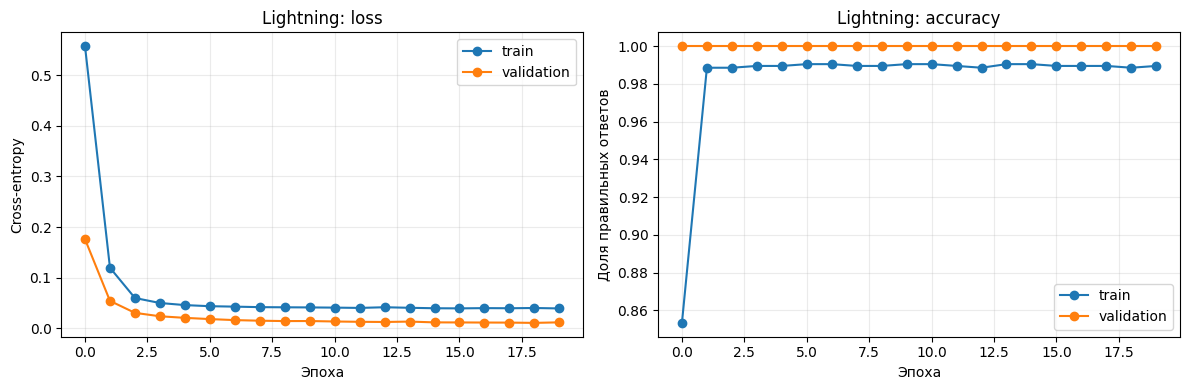

In [26]:
# Читаем CSV-лог Lightning и строим графики train/validation loss и accuracy.
import pandas as pd

# Находим CSV-файл, созданный CSVLogger во время trainer.fit().
metrics_path = Path(csv_logger.log_dir) / "metrics.csv"

# Считываем журнал в таблицу: столбцы соответствуют метрикам, эпохам и иногда шагам обучения.
metrics_df = pd.read_csv(metrics_path)
print("Доступные столбцы:", metrics_df.columns.tolist())

# Проверяем наличие номера эпохи перед группировкой: без этого построить ось эпох нельзя.
if "epoch" in metrics_df.columns:
    # Для каждой эпохи оставляем последнюю записанную строку; логгер может сохранять несколько строк на эпоху.
    epoch_metrics = metrics_df.groupby("epoch", as_index=False).last()

    # На первом графике покажем loss, на втором - accuracy; отдельные if учитывают возможное отсутствие метрики.
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    if "train_loss" in epoch_metrics:
        axes[0].plot(
            epoch_metrics["epoch"],
            epoch_metrics["train_loss"],
            marker="o",
            label="train",
        )

    if "val_loss" in epoch_metrics:
        axes[0].plot(
            epoch_metrics["epoch"],
            epoch_metrics["val_loss"],
            marker="o",
            label="validation",
        )

    axes[0].set_title("Lightning: loss")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    if "train_accuracy" in epoch_metrics:
        axes[1].plot(
            epoch_metrics["epoch"],
            epoch_metrics["train_accuracy"],
            marker="o",
            label="train",
        )

    if "val_accuracy" in epoch_metrics:
        axes[1].plot(
            epoch_metrics["epoch"],
            epoch_metrics["val_accuracy"],
            marker="o",
            label="validation",
        )

    axes[1].set_title("Lightning: accuracy")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Доля правильных ответов")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()
else:
    print("В CSV пока нет столбца epoch; проверьте содержимое файла логов.")

## Сохранение весов, восстановление модели и тестовая оценка

Для модели PyTorch можно сохранить `state_dict()` в отдельный файл. При восстановлении нужно создать экземпляр той же архитектуры и загрузить словарь параметров через `load_state_dict()`. Такой файл удобен, если требуется только использовать обученные веса.

Чекпойнт Lightning содержит больше информации и может быть загружен через `LitClassifier.load_from_checkpoint(...)`. В обоих случаях после загрузки нужно перейти в режим оценки. Для финальной оценки используем тестовую выборку, которая не участвовала в обновлении параметров и настройке модели.

In [27]:
# Сохраняем state_dict, восстанавливаем архитектуру и загружаем лучший чекпойнт Lightning для тестирования.
from pathlib import Path

# Создаём папку для результатов, если её ещё нет.
Path("artifacts").mkdir(exist_ok=True)
weights_path = Path("artifacts") / "tiny_classifier_state_dict.pt"

# state_dict хранит тензоры параметров, но не описание класса модели - архитектуру нужно создать отдельно.
torch.save(manual_model.state_dict(), weights_path)

# Создаём новую модель того же типа и переносим её на выбранное устройство.
restored_model = TinyClassifier().to(device)

# Загружаем веса с отображением на device, чтобы они подходили выбранному CPU/GPU.
state_dict = torch.load(weights_path, map_location=device, weights_only=True)
restored_model.load_state_dict(state_dict)

# Переключаем модель в режим оценки перед вычислением test-метрик.
restored_model.eval()
manual_test_loss, manual_test_accuracy = run_epoch(
    restored_model, test_loader, criterion, device
)

print(
    f"Ручная модель: test loss={manual_test_loss:.4f}, test accuracy={manual_test_accuracy:.3f}"
)

# Отдельно проверяем чекпойнт Lightning: он содержит состояние LightningModule и сохранённые гиперпараметры.
best_checkpoint = checkpoint_callback.best_model_path

# Если Trainer сохранил лучший чекпойнт, восстанавливаем модуль и оцениваем на отложенном test-loader.
if best_checkpoint:
    restored_lightning_model = LitClassifier.load_from_checkpoint(
        best_checkpoint, map_location="cpu"
    )
    test_results = trainer.test(
        restored_lightning_model, dataloaders=test_loader, verbose=False
    )
    print("Тест Lightning:", test_results)
else:
    print("Чекпойнт не найден; проверьте результат trainer.fit().")

Ручная модель: test loss=0.0777, test accuracy=0.969


Testing: |          | 0/? [00:00<?, ?it/s]

Тест Lightning: [{'test_loss': 0.07458510994911194, 'test_accuracy': 0.9688888788223267}]


## Визуализация предсказаний на исходных точках

Для двумерной задачи удобно показать не только метрики, но и то, как модель распределяет точки по классам. Цвет фона показывает класс, который модель предсказывает в каждой точке плоскости; поверх него отображаются реальные объекты. Границы между областями - места, в которых меняется класс с наибольшим логитом.

Такая визуализация полезна именно здесь, потому что у объекта всего два признака. Для моделей с большим числом признаков подобную картину напрямую построить нельзя без проекции на плоскость.

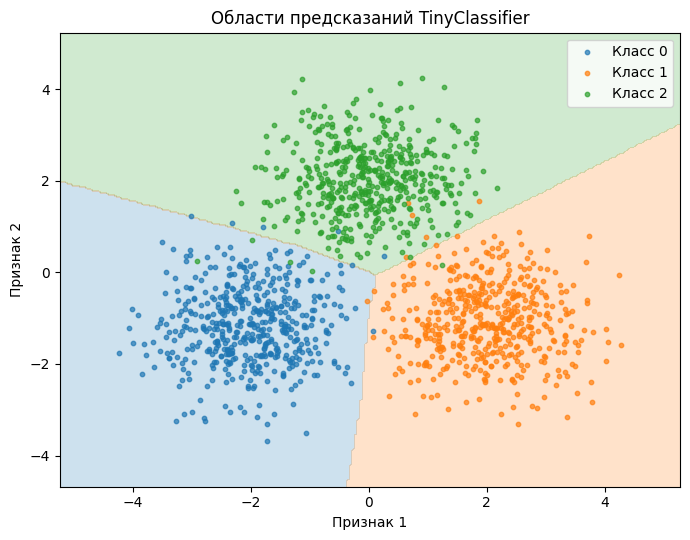

In [28]:
# Рисуем предсказанные области классов и накладываем на них исходные примеры синтетического датасета.
# Используем уже обученную и восстановленную модель, а не обучаем её повторно для визуализации.
from matplotlib.colors import ListedColormap

cmap = ListedColormap(["#1f77b4", "#ff7f0e", "#2ca02c"])

plot_model = restored_model
plot_model.eval()

# Определяем границы рисунка немного шире исходных точек, чтобы не обрезать края облаков.
x_min, x_max = features[:, 0].min().item() - 1.0, features[:, 0].max().item() + 1.0
y_min, y_max = features[:, 1].min().item() - 1.0, features[:, 1].max().item() + 1.0

# Создаём плотную сетку координат; на каждой её точке модель позже предскажет класс.
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 240), np.linspace(y_min, y_max, 240))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device)

# Предсказываем класс каждой точки сетки без построения градиентного графа.
with torch.inference_mode():
    grid_pred = plot_model(grid).argmax(dim=1).cpu().numpy().reshape(xx.shape)

# Цветной фон показывает области классов, а точки поверх него позволяют оценить ошибки классификации.
plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, grid_pred, alpha=0.22, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap)

for class_id in range(3):
    mask = labels_np == class_id
    plt.scatter(
        features_np[mask, 0],
        features_np[mask, 1],
        s=10,
        alpha=0.7,
        label=f"Класс {class_id}",
    )

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Области предсказаний TinyClassifier")
plt.legend()
plt.tight_layout()
plt.show()

## Фиксация конфигурации эксперимента

Чтобы эксперимент можно было описать и повторить, сохраним используемые гиперпараметры и результаты в JSON. В более крупных проектах конфигурацию обычно хранят отдельно от кода и сохраняют вместе с моделью. Здесь мы покажем минимальный вариант: параметры, выбранное устройство, размер датасета и тестовые метрики.

In [29]:
# Сохраняем параметры эксперимента и итоговые метрики в JSON-файл для последующего сравнения запусков.
import json
from pathlib import Path

# Записываем seed, основные гиперпараметры, устройство, размер данных и итоговые метрики в один словарь.
experiment_config = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "manual_epochs": MANUAL_EPOCHS,
    "lightning_epochs": LIGHTNING_EPOCHS,
    "manual_lr": MANUAL_LR,
    "lightning_lr": LIGHTNING_LR,
    "weight_decay": WEIGHT_DECAY,
    "optimizer_baseline": "AdamW",
    "device": str(device),
    "dataset_size": len(dataset),
    "manual_test_loss": manual_test_loss,
    "manual_test_accuracy": manual_test_accuracy,
}

# JSON удобен для последующего сравнения запусков и автоматически сохраняется в папку результатов.
config_path = Path("artifacts") / "experiment_config.json"
config_path.write_text(
    json.dumps(experiment_config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(config_path.read_text(encoding="utf-8"))

{
  "seed": 42,
  "batch_size": 64,
  "manual_epochs": 20,
  "lightning_epochs": 20,
  "manual_lr": 0.01,
  "lightning_lr": 0.01,
  "weight_decay": 0.001,
  "optimizer_baseline": "AdamW",
  "device": "cuda",
  "dataset_size": 1500,
  "manual_test_loss": 0.07765355957878961,
  "manual_test_accuracy": 0.9688888888888889
}


## Основное задание

1. **Тензоры.** Создайте тензоры разных форм и типов, выполните индексирование, изменение формы и broadcasting. Для каждой операции укажите формы входов и результата.
2. **Autograd.** Выберите простую дифференцируемую функцию двух переменных. Сначала запишите её частные производные аналитически, затем сравните результат с `backward()`.
3. **Собственная модель.** Реализуйте класс на основе `nn.Module`, выведите формы входа и выхода и посчитайте число обучаемых параметров.
4. **Данные.** Создайте собственный `Dataset` и `DataLoader`. Проверьте, что `__len__()` и `__getitem__()` возвращают ожидаемые значения и формы.
5. **Ручное обучение.** Реализуйте один шаг по схеме `zero_grad → forward → loss → backward → step`.
6. **Lightning.** Опишите модель через `LightningModule`, запустите обучение через `Trainer` и добавьте логирование и чекпойнт.
7. **Результаты.** Постройте графики train/validation loss и accuracy, сохраните веса, восстановите модель и оцените её на test.

In [30]:
# Задание 1: создайте тензоры, изучите их формы и выполните несколько операций.
# Первая матрица содержит шесть целых чисел; вектор длины 3 пригодится для broadcasting по столбцам.
a_task = torch.arange(6).reshape(2, 3)
b_task = torch.tensor([10, 20, 30])

# Самостоятельно исследуйте результат каждой операции и подпишите формы до и после неё.
# Ваше задание: выведите shape/dtype/numel, выполните индексирование, reshape и broadcasting.

In [31]:
# Задание 2: задайте функцию двух переменных и сравните аналитические производные с autograd.
# Создаём два скалярных тензора, для которых PyTorch будет накапливать производные.
x_task = torch.tensor(2.0, dtype=torch.float32, requires_grad=True)
y_task = torch.tensor(1.0, dtype=torch.float32, requires_grad=True)

# Задайте одну скалярную функцию; после backward() сравните .grad с ручным дифференцированием.
# Ваше задание: определите скалярную функцию, вызовите backward() и сравните градиенты с аналитическим ответом.

In [32]:
# Для выполнения последующих заданий воспользуйтесь предоставленным датасетом.
import pandas as pd

df = pd.read_parquet("../datasets/student_performance.parquet")

feature_names = [
    "attendance",
    "homework",
    "tests",
    "labs",
    "activity",
    "self_study",
    "assignments",
    "missed_classes",
]

target_names = [
    "grade_troechnik",
    "grade_horoshist",
    "grade_otlichnik",
]

X: pd.DataFrame = df[feature_names]
y_one_hot: pd.DataFrame = df[target_names]
y = pd.Series(
    y_one_hot.to_numpy().argmax(axis=1),
    index=y_one_hot.index,
)

print("X:", X.shape)  # (1500, 8)
print("y_one_hot:", y_one_hot.shape)  # (1500, 3)
print("Распределение классов:", y_one_hot.sum().to_dict())

df.head()

X: (1500, 8)
y_one_hot: (1500, 3)
Распределение классов: {'grade_troechnik': 500, 'grade_horoshist': 500, 'grade_otlichnik': 500}


,attendance,homework,tests,labs,activity,self_study,assignments,missed_classes,grade_troechnik,grade_horoshist,grade_otlichnik
0,84.358971,84.858231,72.557571,75.903267,6.417617,6.885142,77.967903,10.898900,0,1,0
1,98.150200,99.825562,92.924957,90.735123,9.094598,12.813385,96.035950,1.231400,0,0,1
2,68.599190,56.878910,52.272404,60.921814,3.540313,2.756527,51.648708,19.054539,1,0,0
3,82.031723,83.181419,81.585976,80.341942,6.781160,6.840117,79.168808,9.980979,0,1,0
4,65.119080,58.842937,44.188740,47.104664,3.595831,2.994307,55.680706,17.306808,1,0,0


In [33]:
# Задание 3: реализуйте собственный nn.Module для классификации трёх классов.
class StudentClassifier(nn.Module):
    # Конструктор должен зарегистрировать слои через атрибуты self, чтобы PyTorch видел их параметры.
    def __init__(
        self,
        in_features: int = 8,
        hidden_features: tuple[int, ...] = (16, 16),
        num_classes: int = 3,
    ) -> None:
        super().__init__()
        # Определите необходимые слои и сохраните их как атрибуты объекта.
        self.sequential = nn.Sequential(...)

    # Прямой проход последовательно применяет слои и возвращает логиты, не метки и не loss.
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Опишите прямой проход и верните логиты формы (batch_size, num_classes).
        ...


# Ваше задание: после реализации проверьте формы входа и выхода и число параметров.

In [34]:
# Задание 4: создайте Dataset и DataLoader для собственных признаков и меток.
class StudentDataset(Dataset[TensorPair]):
    """Dataset для учебных данных задания."""

    # Dataset хранит пары признаков и меток; проверьте число объектов, размерности и тип меток.
    def __init__(self, X: pd.DataFrame, y: pd.DataFrame) -> None: ...

    # Этот метод должен вернуть целое число объектов, доступных по индексам.
    def __len__(self) -> int:
        # Верните число объектов.
        ...

    # Возвращайте один объект и его метку: DataLoader соберёт отдельные элементы в батчи.
    def __getitem__(self, idx: int) -> TensorPair:
        # Верните один объект и его метку.
        ...


# Ваше задание: создайте экземпляр Dataset, проверьте первый объект.
# Разбейте на train/validation/test в соотношении 70%/15%/15%.

In [35]:
# Задание 5: заполните один шаг ручного обучения, используя собственную модель и один батч.
# После реализации StudentClassifier раскомментируйте заготовку ниже.
# Следующие строки задают объекты, с которыми нужно выполнить полный ручной шаг оптимизации.
# student_model = StudentClassifier().to(device)
# student_optimizer = torch.optim.AdamW(student_model.parameters(), lr=MANUAL_LR, weight_decay=WEIGHT_DECAY)
# student_criterion = nn.CrossEntropyLoss()
# Ваше задание: перенесите батч на device, вызовите zero_grad, forward, loss, backward и optimizer.step.

In [36]:
# Задание 6: обучите свою модель через Lightning и сохраните лучший чекпойнт.
# Используйте LitClassifier как ориентир для реализации собственного LightningModule.
# После реализации StudentLitClassifier раскомментируйте заготовку ниже.
# student_lightning_model = StudentLitClassifier(lr=LIGHTNING_LR, weight_decay=WEIGHT_DECAY)

# Callback должен сохранять веса модели с минимальным val_loss.
student_checkpoint = ModelCheckpoint(
    dirpath="checkpoints",
    filename="student-classifier-{epoch:02d}-{val_loss:.4f}",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
)

csv_logger = CSVLogger(save_dir="logs", name="student-classifier")

# Создаём Trainer с небольшим числом эпох и callback сохранения; затем добавьте вызов fit().
student_trainer = L.Trainer(
    max_epochs=LIGHTNING_EPOCHS,
    accelerator="auto",
    devices=1,
    logger=csv_logger,
    callbacks=[student_checkpoint],
)
# Ваше задание: запустите trainer.fit(...) со своими train и validation DataLoader.

In [37]:
# Задание 7: визуализируйте историю обучения и сохраните/восстановите состояние своей модели.
# Используйте историю метрик и сохранённые веса: после загрузки проверьте, что качество не изменилось из-за ошибки восстановления.
# Ваше задание: постройте графики train/validation loss и accuracy, сохраните state_dict,
# восстановите новый экземпляр архитектуры и оцените его на test.

## Контрольные вопросы

1. Что такое тензор и чем он отличается от массива NumPy?
2. Как PyTorch строит вычислительный граф?
3. Для чего предназначены `requires_grad`, `backward()` и `zero_grad()`?
4. Как устроен `nn.Module`?
5. Чем параметры модели отличаются от буферов?
6. Для чего нужны `Dataset` и `DataLoader`?
7. Чем отличаются обучающая, валидационная и тестовая выборки?
8. Что делают функция потерь и оптимизатор?
9. Чем отличаются `train()` и `eval()`?
10. Какие задачи решает PyTorch Lightning?